<a href="https://colab.research.google.com/github/rehanbakmi/Praktikum-Pengolahan-Sinyal-Digital-Unit-7-8/blob/main/unit8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNet
from tensorflow.keras.layers import Input, Layer, Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization, Activation, GlobalAveragePooling2D, AveragePooling2D
from tensorflow.keras.models import Model, Sequential, load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
import json
import os
import pandas as pd
import gdown

file_id = '1qSI7ZqWSTBdbI1I3cwLNIOiFV-kPcNQ1'
gdown.download(f'https://drive.google.com/uc?id={file_id}',
'dataset.zip', quiet=False)

!unzip dataset.zip

dir = '/content/dataset/Covid19-dataset'
train_dir = os.path.join(dir,'train/')
val_dir = os.path.join(dir,'val/')
test_dir = os.path.join(dir,'test/')

# Continue loading data
train_datagen = ImageDataGenerator(rescale=1./255)
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=True
    )

validation_datagen = ImageDataGenerator(rescale=1./255)
validation_generator = validation_datagen.flow_from_directory(
    val_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
    )
test_datagen = ImageDataGenerator(rescale=1./255)
test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
    )

model = MobileNet(input_shape=(224,224, 3), weights='imagenet', include_top=False)

for layer in model.layers:
  layer.trainable = False

xi = model.output
xi = GlobalAveragePooling2D()(xi)
xi = Dense(256, activation='relu')(xi)
xi = Dropout(0.3)(xi)
xi = Dense(128, activation='relu')(xi)
xi = Dropout(0.3)(xi)
output = Dense(3, activation='softmax')(xi)
model = Model(inputs=model.input, outputs=output)
model.summary()

opt = Adam(learning_rate=0.0001)
# compile model
model.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])

# Train the model
history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=30
    )



Downloading...
From (original): https://drive.google.com/uc?id=1qSI7ZqWSTBdbI1I3cwLNIOiFV-kPcNQ1
From (redirected): https://drive.google.com/uc?id=1qSI7ZqWSTBdbI1I3cwLNIOiFV-kPcNQ1&confirm=t&uuid=e1e383bf-e32a-472d-b72f-c2ba2b93f936
To: /content/dataset.zip
100%|██████████| 162M/162M [00:00<00:00, 212MB/s]


Archive:  dataset.zip
replace dataset/Covid19-dataset/test/Covid/0100.jpeg? [y]es, [n]o, [A]ll, [N]one, [r]ename: A
  inflating: dataset/Covid19-dataset/test/Covid/0100.jpeg  
  inflating: dataset/Covid19-dataset/test/Covid/0102.jpeg  
  inflating: dataset/Covid19-dataset/test/Covid/0105.png  
  inflating: dataset/Covid19-dataset/test/Covid/0106.jpeg  
  inflating: dataset/Covid19-dataset/test/Covid/0108.jpeg  
  inflating: dataset/Covid19-dataset/test/Covid/0120.jpg  
  inflating: dataset/Covid19-dataset/test/Covid/094.png  
  inflating: dataset/Covid19-dataset/test/Covid/096.png  
  inflating: dataset/Covid19-dataset/test/Covid/098.jpeg  
  inflating: dataset/Covid19-dataset/test/Covid/auntminnie-2020_01_31_20_24_2322_2020_01_31_x-ray_coronavirus_US.jpg  
  inflating: dataset/Covid19-dataset/test/Covid/auntminnie-a-2020_01_28_23_51_6665_2020_01_28_Vietnam_coronavirus.jpeg  
  inflating: dataset/Covid19-dataset/test/Covid/auntminnie-b-2020_01_28_23_51_6665_2020_01_28_Vietnam_coronavir

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 112, 112, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_bn (BatchNormalization)   │ (None, 112, 112, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_relu (ReLU)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1 (DepthwiseConv2D)     │ (None, 112, 112, 32)   │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1_bn                    │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1_relu (ReLU)           │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1 (Conv2D)              │ (None, 112, 112, 64)   │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1_bn                    │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1_relu (ReLU)           │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pad_2 (ZeroPadding2D)      │ (None, 113, 113, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2 (DepthwiseConv2D)     │ (None, 56, 56, 64)     │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2_bn                    │ (None, 56, 56, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2_relu (ReLU)           │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2 (Conv2D)              │ (None, 56, 56, 128)    │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2_bn                    │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2_relu (ReLU)           │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3 (DepthwiseConv2D)     │ (None, 56, 56, 128)    │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3_bn                    │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3_relu (ReLU)           │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_3 (Conv2D)              │ (None, 56, 56, 128)    │        16,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_3_bn                    │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 3,524,547 (13.45 MB)

 Trainable params: 295,683 (1.13 MB)

 Non-trainable params: 3,228,864 (12.32 MB)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 50s 4s/step - accuracy: 0.3220 - loss: 1.3559 - val_accuracy: 0.5667 - val_loss: 0.9421
Epoch 2/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 977ms/step - accuracy: 0.4585 - loss: 1.1088 - val_accuracy: 0.6111 - val_loss: 0.7856
Epoch 3/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 715ms/step - accuracy: 0.5760 - loss: 1.0341 - val_accuracy: 0.7667 - val_loss: 0.6168
Epoch 4/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 818ms/step - accuracy: 0.6368 - loss: 0.7424 - val_accuracy: 0.8556 - val_loss: 0.5477
Epoch 5/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 701ms/step - accuracy: 0.6746 - loss: 0.7496 - val_accuracy: 0.8333 - val_loss: 0.5022
Epoch 6/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 719ms/step - accuracy: 0.7421 - loss: 0.6877 - val_accuracy: 0.8556 - val_loss: 0.4464
Epoch 7/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 834ms/step - accuracy: 0.7076 - loss: 0.6298 - val_accuracy: 0.9222 - val_loss: 0.3843
Epoch 8/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 757ms/step - accuracy: 0.7905 - loss: 0.5650 - val_accuracy: 0.9222 - val_loss: 0

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 561ms/step - accuracy: 0.8750 - loss: 0.2444
Test accuracy: 0.875


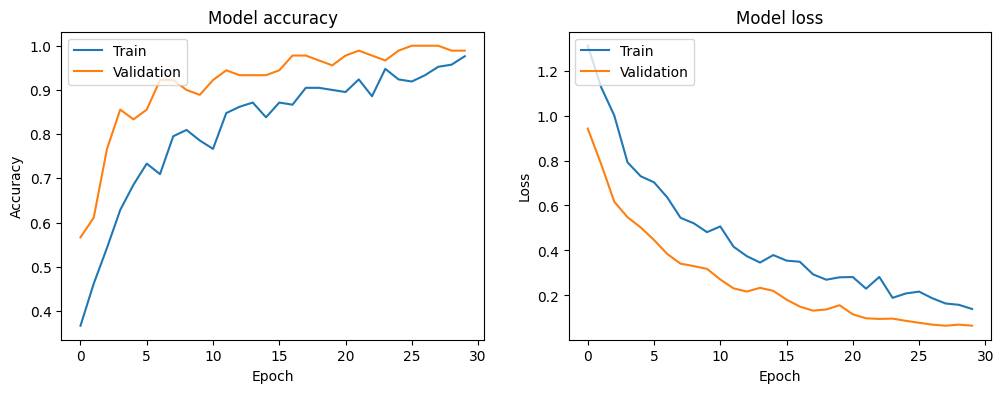

2/2 ━━━━━━━━━━━━━━━━━━━━ 13s 10s/step


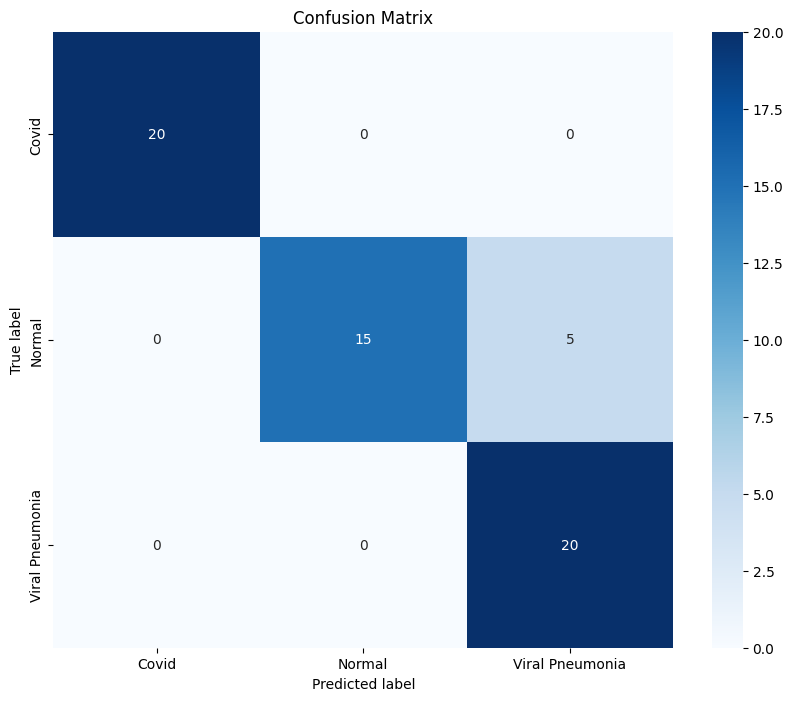

Classification Report
                 precision    recall  f1-score   support

          Covid       1.00      1.00      1.00        20
         Normal       1.00      0.75      0.86        20
Viral Pneumonia       0.80      1.00      0.89        20

       accuracy                           0.92        60
      macro avg       0.93      0.92      0.92        60
   weighted avg       0.93      0.92      0.92        60



In [ ]:
#UJI AKURASI
# Evaluate the model on the test data
test_loss, test_acc = model.evaluate(test_generator,
steps=test_generator.samples // test_generator.batch_size)
print(f'Test accuracy: {test_acc}')
#Lihat History Fine-Tuning
# Plot training & validation accuracy values
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()
#TAMPILKAN CONFUSION MATRIX
# Confusion Matrix
Y_pred = model.predict(test_generator, test_generator.samples //
test_generator.batch_size+1)
y_pred = np.argmax(Y_pred, axis=1)
# Get the ground truth
y_true = test_generator.classes
# Compute confusion matrix
cm = confusion_matrix(y_true, y_pred)
# Plot the confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
xticklabels=test_generator.class_indices,
yticklabels=test_generator.class_indices)
plt.title('Confusion Matrix')
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.show()
# Classification Report
print('Classification Report')
target_names = list(test_generator.class_indices.keys())
print(classification_report(y_true, y_pred,
target_names=target_names))